<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN4/blob/main/DNN5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 監査結果（実装変更前）

- 設定セルで `EPOCHS=2`, `PATIENCE=2`。ReduceLROnPlateau は検証損失、factor 0.5, patience 15。
- 入力は67次元。特徴量の並びは `[nx, ny, load, floors, X10, Y10, X mask10, Y mask10, cumulative floor heights10, height mask10, 3 presence flags]`。固定範囲で0–1化し、clip後にスパン・高さをマスク。範囲外値は飽和し、値の差が失われる。
- `parse_targets` はCSV中の名称をカタログ名と完全一致させる。未知名称は例外。カタログ順を出力IDに使い、候補順との対応は維持されている。
- 学習は期待寸法のMSEで梁1 + 柱2、検証は寸法MSEで梁1 + 柱1。目的関数が不整合。推論のargmaxは期待寸法MSEの最小化と一致する保証がない。
- データはtrain 5,196 / val 1,113 / test 1,115。分割間の数値ID重複は train/val 771、train/test 771、val/test 158。設計条件タプルの重複は各ペア128。数値IDの意味を示す生成仕様は確認できず、同一系列とは断定しない。
- `feature_min/max` は保存するが、チェックポイント再ロード処理はなく、`reuse_checkpoint=False` 固定。最良重みはメモリ内だけで保持され、最終保存はtest評価後。
- seed 42とcuDNN決定性は設定されるが、DataLoader generator/worker seed、PyTorch/CUDA環境情報は未記録。
- 信頼度は未校正softmax最大値。異常判定は0.50固定とtrain範囲外のORで、誤予測や希少条件と区別しない。
- ノートブックの保存済み出力は過去環境の結果であり、今回のWindows環境ではPython実行環境を起動できず再学習・数値評価は未実施。

## 修正計画

まず早期終了と検証ログを改善し、損失方式と梁柱重みを設定可能にする。分割は固定し、未知のID仕様を仮定した再分割は行わない。評価CSVや多方式の比較実験は実行環境確認後に行う。

#概要**修正後の実施状況:** 監査メモを先頭に追加し、最大400 epoch・patience 35、梁柱重みと3種の損失を選べる設定、学習履歴の項目を追加。実際の性能比較はノートブック実行が必要です。

#github

In [33]:
# !git config --global user.name "usumakikai8-bot"
# !git config --global user.email "usumakikai8@gmail.com"

#第1段階セル（ライブラリのインポート、マウント、設定）

In [34]:
# ライブラリのインポート
import csv
import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset


In [35]:
#google driveのマウント
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
%pwd

'/content/drive/My Drive/research/DNN5'

In [37]:
# Drive 上の作業フォルダ。必要なときだけ変更してください。
%cd /content/drive/MyDrive/research/DNN5


/content/drive/MyDrive/research/DNN5


In [38]:
%pwd

'/content/drive/MyDrive/research/DNN5'

path設定は非常に重要だ。フォルダ構成に注意する。

In [39]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
# Colab: dataset3 と catalog を Google Drive に配置してください。
DATASET_ROOT = Path(r'C:/Research/dataset3') if Path(r'C:/Research/dataset3').exists() else Path('/content/drive/MyDrive/research/dataset3')
CATALOG_ROOT = DATASET_ROOT / 'catalog'
OUTPUT_DIR = PROJECT_ROOT / 'dnn_result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /content/drive/MyDrive/research/DNN5
DATASET_ROOT: /content/drive/MyDrive/research/dataset3
CATALOG_ROOT: /content/drive/MyDrive/research/dataset3/catalog
OUTPUT_DIR: /content/drive/MyDrive/research/DNN5/dnn_result


In [40]:
SEED = 42
BATCH_SIZE = 256
EPOCHS = 400
PATIENCE = 35
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
MAX_SPANS = 10
MIN_SPAN_MM = 4000.0  # 北川さんのPDFを確認後に根拠と値を照合してください
MAX_SPAN_MM_NORMALIZATION = 12000.0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'{DEVICE=}')
missing = [str(DATASET_ROOT / s) for s in ('train', 'val', 'test') if not (DATASET_ROOT / s).is_dir()]
if missing: raise FileNotFoundError(f'train/val/test が見つかりません: {missing}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'カタログCSVのフォルダがありません: {CATALOG_ROOT}。梁H形鋼カタログ.csv と 柱角形鋼管カタログ.csv を配置してください。')

LOSS_MODE = 'dimension_mse'  # 'cross_entropy' / 'combined' も選択可能
LAMBDA_DIM = 0.1
SECTION_WEIGHT_H = 1.0
SECTION_WEIGHT_BOX = 2.0


DEVICE=device(type='cuda')


#第2セル（各種関数定義、カタログの読み込み）

In [41]:
def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def read_text(path: Path) -> str:
    for encoding in ('utf-8-sig', 'utf-8', 'cp932'):
        try: return path.read_text(encoding=encoding)
        except UnicodeDecodeError: pass
    return path.read_text(encoding='utf-8', errors='replace')

def read_catalog(path: Path, kind: str) -> list[dict]:
    rows = list(csv.DictReader(read_text(path).splitlines()))
    name_col = '断面名'
    cols = ('呼び梁せいH(mm)', '呼び幅B(mm)', '腹板厚tw(mm)', 'フランジ厚tf(mm)') if kind == 'h' else ('呼び柱径D(mm)', '板厚t(mm)')
    if not rows or not {name_col, *cols}.issubset(rows[0]):
        raise ValueError(f'カタログCSVの列が想定と異なります: {path}')
    return [{'name': r[name_col].strip(), 'values': tuple(float(r[c]) for c in cols)} for r in rows]

H_CATALOG = read_catalog(CATALOG_ROOT / '梁H形鋼カタログ.csv', 'h')
BOX_CATALOG = read_catalog(CATALOG_ROOT / '柱角形鋼管カタログ.csv', 'box')
print(f'H catalog: {len(H_CATALOG)}, box catalog: {len(BOX_CATALOG)}')


H catalog: 35, box catalog: 38


#第3セル（データ前処理、データローダーの作成）

荷重の正規化範囲を(0, 10)に変更。

In [42]:
FILENAME_RE = re.compile(r'^(?P<id>[0-9]+)_(?P<floor>[0-9]+)階_X(?P<nx>[0-9]+)_Y(?P<ny>[0-9]+)_荷重(?P<load>[0-9.]+)(?: \(\d+\))?\.csv$')

def table_after_marker(text, marker):
    lines=text.splitlines(); start=next(i for i,line in enumerate(lines) if line.strip()==marker)
    data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal, kind):
    name=nominal.strip(); cat=H_CATALOG if kind=='h' else BOX_CATALOG
    if name not in {r['name'] for r in cat}: raise ValueError(f'カタログにない断面名: {name}')
    return name

def parse_targets(path):
    text=read_text(path); out={}; _,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        for symbol,section in zip(('C1','C2','C3','C4'),row[1:]):
            if section.strip(): out[f'column:{row[0].strip()}:{symbol}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): out[f'beam:{row[0].strip()}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return out

def features_from_file(path):
    m=FILENAME_RE.fullmatch(re.sub(r' \(\d+\)(?=\.csv$)','',path.name))
    if not m: raise ValueError(f'想定外のファイル名: {path.name}')
    nx,ny,floors=int(m['nx']),int(m['ny']),int(m['floor']); load=float(m['load']); text=read_text(path)
    sh,srows=table_after_marker(text,'name=スパン割'); sc=[i for i,h in enumerate(sh) if h.startswith('スパン')]
    sp={r[0].strip():[float(r[i]) for i in sc if i<len(r) and r[i].strip()] for r in srows}; sx,sy=sp['X'],sp['Y']
    if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'スパン数不一致: {path.name}')
    if max(nx,ny,floors)>MAX_SPANS: raise ValueError(f'MAX_SPANS超過: {path.name}')
    if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン未満: {path.name}')
    xl=sx+[0.]*(MAX_SPANS-nx); yl=sy+[0.]*(MAX_SPANS-ny); xm=[1.]*nx+[0.]*(MAX_SPANS-nx); ym=[1.]*ny+[0.]*(MAX_SPANS-ny)
    hh,hr=table_after_marker(text,'name=階高'); hi=next(i for i,h in enumerate(hh) if '階高' in h); hd={r[0].strip():float(r[hi]) for r in hr if len(r)>hi and r[hi].strip()}
    z=[]; acc=0.
    for f in range(1,floors+1):
        acc+=hd[f'{f}FL']; z.append(acc)
    zm=[1.]*floors+[0.]*(MAX_SPANS-floors); z += [0.]*(MAX_SPANS-floors)
    return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,*z,*zm,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict

def load_split(split):
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    samples=[Sample(p.name,features_from_file(p),parse_targets(p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({k for sm in train_samples for k in sm.targets})
SLOT_TYPES=[next(sm.targets[k][0] for sm in train_samples if k in sm.targets) for k in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,10),(1,10)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS)+[(0,40000)]*MAX_SPANS+[(0,1)]*MAX_SPANS+[(0,1)]*3
feature_min=np.asarray([a for a,b in FEATURE_NORMALIZATION],dtype=np.float32); feature_max=np.asarray([b for a,b in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
FEATURE_NAMES = ['nx','ny','load','floors'] + [f'x_span_{i+1}' for i in range(MAX_SPANS)] + [f'y_span_{i+1}' for i in range(MAX_SPANS)] + [f'x_valid_{i+1}' for i in range(MAX_SPANS)] + [f'y_valid_{i+1}' for i in range(MAX_SPANS)] + [f'cumulative_height_{i+1}' for i in range(MAX_SPANS)] + [f'height_valid_{i+1}' for i in range(MAX_SPANS)] + ['has_x','has_y','has_floors']
if len(FEATURE_NAMES) != len(FEATURE_NORMALIZATION):
    raise ValueError(f'feature name/normalization mismatch: {len(FEATURE_NAMES)} vs {len(FEATURE_NORMALIZATION)}')
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,i):
        sm=self.samples[i]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            arr=yh if kind=='h' else yb
            if slot not in sm.targets: arr.append(-100)
            else:
                _,name=sm.targets[slot]; arr.append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sm.x-feature_min)/feature_range,0,1); x[24:34]*=x[64]
        x[34:44]*=x[65]
        x[44:54]*=x[54:64]
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sm.file_name
train_loader=DataLoader(SectionDataset(train_samples),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(SectionDataset(val_samples),batch_size=BATCH_SIZE); test_loader=DataLoader(SectionDataset(test_samples),batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Yスパン・有効マスク・z高さ・z有効マスク), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')


train: 5200 files
val: 1113 files
test: 1115 files
入力特徴量=67 (X/Yスパン・有効マスク・z高さ・z有効マスク), 梁slot=32, 柱slot=16


In [43]:
# Raw feature range audit (before clipping/normalization)
raw_train = np.stack([sm.x for sm in train_samples])
raw_lo, raw_hi = raw_train.min(axis=0), raw_train.max(axis=0)
print('Feature index map:', list(enumerate(FEATURE_NAMES)))
for split_name, split_samples in [('val', val_samples), ('test', test_samples)]:
    raw = np.stack([sm.x for sm in split_samples])
    outside_by_feature = (raw < raw_lo) | (raw > raw_hi)
    outside_rows = outside_by_feature.any(axis=1)
    print(f'{split_name}: outside train feature range {outside_rows.sum()}/{len(raw)} ({outside_rows.mean():.2%})')
    print(pd.DataFrame({'feature': FEATURE_NAMES, 'outside_count': outside_by_feature.sum(0), 'n': len(raw)}).query('outside_count > 0').to_string(index=False))
for label, catalog in [('beam', H_CATALOG), ('column', BOX_CATALOG)]:
    dims = [tuple(row['values']) for row in catalog]
    duplicate_dims = {d: n for d, n in Counter(dims).items() if n > 1}
    print(f'{label}: catalog_names={len(catalog)}, duplicate_dimension_groups={duplicate_dims}')

Feature index map: [(0, 'nx'), (1, 'ny'), (2, 'load'), (3, 'floors'), (4, 'x_span_1'), (5, 'x_span_2'), (6, 'x_span_3'), (7, 'x_span_4'), (8, 'x_span_5'), (9, 'x_span_6'), (10, 'x_span_7'), (11, 'x_span_8'), (12, 'x_span_9'), (13, 'x_span_10'), (14, 'y_span_1'), (15, 'y_span_2'), (16, 'y_span_3'), (17, 'y_span_4'), (18, 'y_span_5'), (19, 'y_span_6'), (20, 'y_span_7'), (21, 'y_span_8'), (22, 'y_span_9'), (23, 'y_span_10'), (24, 'x_valid_1'), (25, 'x_valid_2'), (26, 'x_valid_3'), (27, 'x_valid_4'), (28, 'x_valid_5'), (29, 'x_valid_6'), (30, 'x_valid_7'), (31, 'x_valid_8'), (32, 'x_valid_9'), (33, 'x_valid_10'), (34, 'y_valid_1'), (35, 'y_valid_2'), (36, 'y_valid_3'), (37, 'y_valid_4'), (38, 'y_valid_5'), (39, 'y_valid_6'), (40, 'y_valid_7'), (41, 'y_valid_8'), (42, 'y_valid_9'), (43, 'y_valid_10'), (44, 'cumulative_height_1'), (45, 'cumulative_height_2'), (46, 'cumulative_height_3'), (47, 'cumulative_height_4'), (48, 'cumulative_height_5'), (49, 'cumulative_height_6'), (50, 'cumulative_h

# モデル次元: 入力=4基本条件+X/Y各10スパン長+各10有効マスク+X/Y/Z部材有無。
# 128は隠れ層ユニット数、出力slot数×カタログ数はslotごとの候補断面スコア。
# 部材がないslotは教師ラベル-100にして損失計算から除外します。

In [44]:
class SimpleDNN(nn.Module):
    def __init__(self,n_features,n_h_slots,n_box_slots,n_h_catalog,n_box_catalog):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(n_features,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU())
        self.h_head=nn.Linear(128,n_h_slots*n_h_catalog); self.box_head=nn.Linear(128,n_box_slots*n_box_catalog)
        self.n_h_slots=n_h_slots; self.n_h_catalog=n_h_catalog; self.n_box_slots=n_box_slots; self.n_box_catalog=n_box_catalog
    def forward(self,x):
        h=self.net(x)
        return self.h_head(h).view(-1,self.n_h_slots,self.n_h_catalog),self.box_head(h).view(-1,self.n_box_slots,self.n_box_catalog)
model=SimpleDNN(len(FEATURE_NORMALIZATION),N_H_SLOTS,N_BOX_SLOTS,len(H_CATALOG),len(BOX_CATALOG)).to(DEVICE)
H_DIMENSIONS=torch.tensor([r['values'] for r in H_CATALOG],dtype=torch.float32,device=DEVICE)
BOX_DIMENSIONS=torch.tensor([r['values'] for r in BOX_CATALOG],dtype=torch.float32,device=DEVICE)
def section_dimension_mse(logits,targets,dimensions):
    valid=targets.ne(-100)
    if not valid.any(): return logits.sum()*0.0
    expected=logits.softmax(-1)@dimensions; truth=dimensions[targets.clamp_min(0)]
    return ((expected-truth).square().mean(-1)*valid).sum()/valid.sum()
print(model)
print(f'入力={len(FEATURE_NORMALIZATION)} → 128 → 128 → 梁slot×{len(H_CATALOG)} / 柱slot×{len(BOX_CATALOG)} logits')

SimpleDNN(
  (net): Sequential(
    (0): Linear(in_features=67, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (h_head): Linear(in_features=128, out_features=1120, bias=True)
  (box_head): Linear(in_features=128, out_features=608, bias=True)
)
入力=67 → 128 → 128 → 梁slot×35 / 柱slot×38 logits


#第5セル（評価関数、学習ループ、グラフ描画）

epoch=001 train_loss=9094.4810 val_loss=8573.4762 val_acc=0.043
epoch=020 train_loss=2580.8928 val_loss=2503.4700 val_acc=0.071
epoch=040 train_loss=2294.3762 val_loss=2255.6492 val_acc=0.083
epoch=060 train_loss=2142.8910 val_loss=2104.1422 val_acc=0.084
epoch=080 train_loss=2094.8880 val_loss=2089.4616 val_acc=0.088
epoch=100 train_loss=2058.0955 val_loss=2029.7359 val_acc=0.092
epoch=120 train_loss=2018.4069 val_loss=2005.5455 val_acc=0.096
epoch=140 train_loss=2006.8028 val_loss=1971.2616 val_acc=0.099
epoch=160 train_loss=1953.6282 val_loss=1976.6437 val_acc=0.102
epoch=180 train_loss=1929.6189 val_loss=1938.2297 val_acc=0.101
epoch=200 train_loss=1908.2966 val_loss=1916.6038 val_acc=0.100
epoch=220 train_loss=1888.7554 val_loss=1921.8676 val_acc=0.097
epoch=240 train_loss=1873.5433 val_loss=1868.6987 val_acc=0.099
epoch=260 train_loss=1864.4813 val_loss=1859.1194 val_acc=0.103
epoch=280 train_loss=1850.7762 val_loss=1870.9759 val_acc=0.103
epoch=300 train_loss=1863.0813 val_loss=

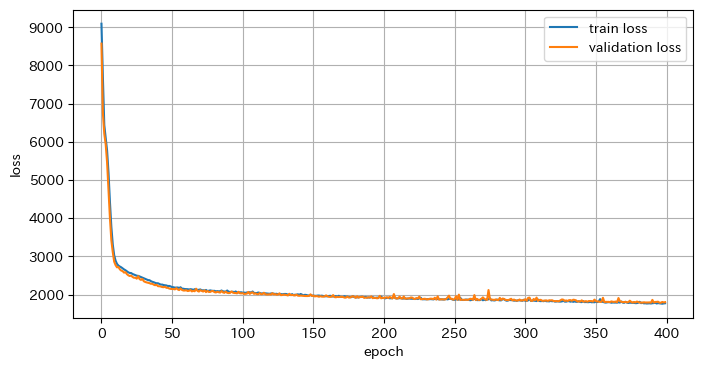

In [45]:
# 1. 評価・推論処理 (evaluate)
def section_objective(logits, targets, dimensions):
    valid = targets.ne(-100)
    if not valid.any():
        return logits.sum() * 0.0
    if LOSS_MODE == 'cross_entropy':
        return nn.functional.cross_entropy(logits[valid], targets[valid])
    dim_loss = section_dimension_mse(logits, targets, dimensions)
    if LOSS_MODE == 'dimension_mse':
        return dim_loss
    if LOSS_MODE == 'combined':
        ce_loss = nn.functional.cross_entropy(logits[valid], targets[valid])
        return ce_loss + LAMBDA_DIM * dim_loss
    raise ValueError(f'Unknown LOSS_MODE={LOSS_MODE!r}')
@torch.no_grad()
def evaluate(loader, export_rows=False):
    model.eval()

    total, correct, full_correct, loss_sum = 0, 0, 0, 0.0

    # 梁・柱の正解数
    h_total, h_correct = 0, 0
    box_total, box_correct = 0, 0

    # 階ごとの正解数
    floor_stats = {}

    records = []

    for x, y_h, y_box, names in loader:
        x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)

        logits_h, logits_box = model(x)

        loss_h = section_objective(logits_h, y_h, H_DIMENSIONS)
        loss_box = section_objective(logits_box, y_box, BOX_DIMENSIONS)
        # 評価用ロス
        loss = SECTION_WEIGHT_H * loss_h + SECTION_WEIGHT_BOX * loss_box

        pred_h = torch.argmax(logits_h, dim=-1)  # 最終予測はカタログ候補から1つ選ぶ
        pred_box = torch.argmax(logits_box, dim=-1)  # 最終予測はカタログ候補から1つ選ぶ

        # --------------------------------
        # 全スロットのAccuracy
        # --------------------------------
        all_pred = torch.cat([pred_h, pred_box], dim=1)
        all_true = torch.cat([y_h, y_box], dim=1)

        valid = all_true.ne(-100)
        matches = all_pred.eq(all_true) & valid
        correct += matches.sum().item()
        total += valid.sum().item()

        # 建物に存在するスロットだけで完全一致を判定
        full_correct += (matches | ~valid).all(1).sum().item()

        # --------------------------------
        # 梁（H）のAccuracy
        # --------------------------------
        h_valid = y_h.ne(-100)
        h_correct += (pred_h.eq(y_h) & h_valid).sum().item()
        h_total += h_valid.sum().item()

        # --------------------------------
        # 柱（BOX）のAccuracy
        # --------------------------------
        box_valid = y_box.ne(-100)
        box_correct += (pred_box.eq(y_box) & box_valid).sum().item()
        box_total += box_valid.sum().item()

        # --------------------------------
        # 階ごとのAccuracy
        # --------------------------------
        for slot_idx, (slot, kind) in enumerate(zip(SLOTS, SLOT_TYPES)):

            # slot名から階を取得
            if ':' in slot:
                floor = slot.split(':')[1]
            else:
                floor = slot

            if floor not in floor_stats:
                floor_stats[floor] = {
                    'correct': 0,
                    'total': 0
                }

            if kind == 'h':
                pred = pred_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

                true = y_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

            else:
                pred = pred_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

                true = y_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

            active = true.ne(-100)
            floor_stats[floor]['correct'] += (pred.eq(true) & active).sum().item()
            floor_stats[floor]['total'] += active.sum().item()

        loss_sum += loss.item() * len(names)

        # --------------------------------
        # CSV出力用データ
        # --------------------------------
        if export_rows:
            for b, name in enumerate(names):

                hi = bi = 0

                for slot, kind in zip(SLOTS, SLOT_TYPES):

                    if kind == 'h':
                        p = pred_h[b, hi].item()
                        t = y_h[b, hi].item()
                        hi += 1
                        catalog = H_CATALOG

                    else:
                        p = pred_box[b, bi].item()
                        t = y_box[b, bi].item()
                        bi += 1
                        catalog = BOX_CATALOG

                    # -100 はその建物に存在しないスロットを示すため、出力対象外
                    if t == -100:
                        continue
                    if not (0 <= t < len(catalog)):
                        raise ValueError(
                            f'Invalid target index: file={name}, slot={slot}, '
                            f'target_id={t}, catalog_size={len(catalog)}, type={kind}'
                        )
                    if not (0 <= p < len(catalog)):
                        raise ValueError(
                            f'Invalid prediction index: file={name}, slot={slot}, '
                            f'predicted_id={p}, catalog_size={len(catalog)}, type={kind}'
                        )
                    records.append({
                        'file_name': name,
                        'slot': slot,
                        'section_type': kind,
                        'predicted_catalog': catalog[p]['name'],
                        'true_catalog': catalog[t]['name'],
                        'is_correct': p == t
                    })

    n_files = len(loader.dataset)

    return {
        'loss': loss_sum / n_files,

        # 全体
        'slot_accuracy': correct / max(total, 1),

        # 梁
        'h_accuracy': h_correct / max(h_total, 1),

        # 柱
        'box_accuracy': box_correct / max(box_total, 1),

        # 建物完全一致
        'building_exact_match': full_correct / n_files,

        # 階ごとの統計
        'floor_stats': floor_stats,

        'records': records
    }

# 既存の互換チェックポイントがあればロードし、学習を省略します。
CHECKPOINT_PATH = OUTPUT_DIR / 'best_section_dnn.pt'
CHECKPOINT_SIGNATURE = {
    'feature_normalization': FEATURE_NORMALIZATION,
    'slots': SLOTS,
    'slot_types': SLOT_TYPES,
    'h_catalog': H_CATALOG,
    'box_catalog': BOX_CATALOG,
    'max_spans': MAX_SPANS,
    'min_span_mm': MIN_SPAN_MM,
    'loss_mode': LOSS_MODE, 'lambda_dim': LAMBDA_DIM,
    'section_weights': (SECTION_WEIGHT_H, SECTION_WEIGHT_BOX),
}
# 重み設定を変更したため、以前のキャッシュをロードせずに再学習させます
reuse_checkpoint = False

if not reuse_checkpoint:
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15)
    best_state, best_val, wait = None, float('inf'), 0
    history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_slot_accuracy': [], 'val_h_accuracy': [], 'val_box_accuracy': [], 'val_building_exact_match': [], 'learning_rate': []}

    #3. 学習ループ（Training Loop）
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x, y_h, y_box, _ in train_loader:
            x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits_h, logits_box = model(x)

            # H梁とBOX柱の損失を別々に計算（指示通りBOXの重みを2倍に設定）
            loss_h = section_objective(logits_h, y_h, H_DIMENSIONS)
            loss_box = section_objective(logits_box, y_box, BOX_DIMENSIONS)
            loss = SECTION_WEIGHT_H * loss_h + SECTION_WEIGHT_BOX * loss_box

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(x)
        val = evaluate(val_loader)
        train_loss /= len(train_loader.dataset)
        scheduler.step(val['loss'])
        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val['loss'])
        history['val_slot_accuracy'].append(val['slot_accuracy'])
        history['val_h_accuracy'].append(val['h_accuracy'])
        history['val_box_accuracy'].append(val['box_accuracy'])
        history['val_building_exact_match'].append(val['building_exact_match'])
        history['learning_rate'].append(optimizer.param_groups[0]['lr'])
        if val['loss'] < best_val:
            best_val, wait = val['loss'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if epoch == 1 or epoch % 20 == 0:
            print(f'epoch={epoch:03d} train_loss={train_loss:.4f} val_loss={val["loss"]:.4f} val_acc={val["slot_accuracy"]:.3f}')
        if wait >= PATIENCE:
            print(f'Early stopping at epoch {epoch}; best val loss={best_val:.4f}')
            break


#4. 最良モデルの復元と学習曲線のプロット
if not reuse_checkpoint:
    model.load_state_dict(best_state)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / 'training_history.csv', index=False, encoding='utf-8-sig')
plt.figure(figsize=(8, 4))
plt.plot(history['train_loss'], label='train loss')
plt.plot(history['val_loss'], label='validation loss')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.grid(); plt.show()

#第6セル（テストデータの評価、ファイル保存）

In [46]:
# 1. テストデータの評価と結果表示
test_result = evaluate(test_loader, export_rows=True)

print("=" * 50)
print("Test Results")
print("=" * 50)

print(f"Loss                  : {test_result['loss']:.4f}")
print(f"Slot Accuracy         : {test_result['slot_accuracy']:.4f}")
print(f"H (Beam) Accuracy     : {test_result['h_accuracy']:.4f}")
print(f"BOX (Column) Accuracy : {test_result['box_accuracy']:.4f}")
print(f"Building Exact Match  : {test_result['building_exact_match']:.4f}")

print("\n" + "=" * 50)
print("Accuracy by Floor")
print("=" * 50)

for floor, stats in test_result['floor_stats'].items():
    accuracy = stats['correct'] / stats['total']
    print(
        f"{floor:>4s} : "
        f"{accuracy:.4f} "
        f"({stats['correct']}/{stats['total']})"
    )

#2. 予測結果のCSVファイルへの書き出し
predictions = pd.DataFrame(test_result['records'])
pred_path = OUTPUT_DIR / 'test_catalog_predictions.csv'
predictions.to_csv(pred_path, index=False, encoding='utf-8-sig')

#3. チェックポイント（学習済みモデル等）の保存
checkpoint = {
    'model_state_dict': model.state_dict(),
    'checkpoint_signature': CHECKPOINT_SIGNATURE,
    'feature_min': feature_min,  # 最小値を保存
    'feature_max': feature_max,
    'feature_normalization': FEATURE_NORMALIZATION,
    'slots': SLOTS,
    'slot_types': SLOT_TYPES,
    'h_catalog': H_CATALOG,
    'box_catalog': BOX_CATALOG,
}
torch.save(checkpoint, CHECKPOINT_PATH)

#4. 完了メッセージと予測結果プレビューの表示
print(f'Saved: {pred_path}')
print(predictions.head(20).to_string(index=False))

Test Results
Loss                  : 1860.8217
Slot Accuracy         : 0.0950
H (Beam) Accuracy     : 0.1333
BOX (Column) Accuracy : 0.0310
Building Exact Match  : 0.0000

Accuracy by Floor
 2FL : 0.1279 (1524/11912)
 3FL : 0.0601 (716/11912)
 4FL : 0.1022 (611/5976)
 RFL : 0.1171 (873/7452)
 1FL : 0.0534 (238/4460)
Saved: /content/drive/MyDrive/research/DNN5/dnn_result/test_catalog_predictions.csv
            file_name         slot section_type  predicted_catalog       true_catalog  is_correct
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX1            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX2            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX3            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX4            h H-500x200x10x16x13 H-500x200x10x16x13        True
0006_4階_X2_Y3_荷重8.csv beam:2FL:GY1            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2

#第7セル（結果をグラフで可視化）

In [47]:
!pip install japanize-matplotlib

In [48]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from google.colab import files
#コード中で、
import japanize_matplotlib

#上書きされたあとで、
japanize_matplotlib.japanize()

異常候補（要確認）: 1115 / 1115


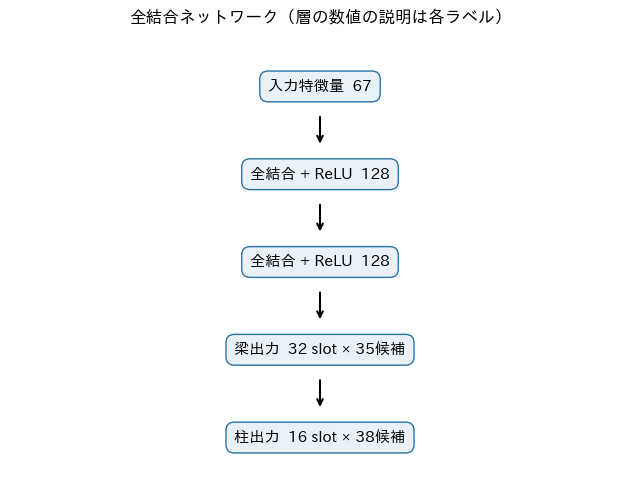

異常候補CSV: /content/drive/MyDrive/research/DNN5/dnn_result/anomaly_candidates.csv


In [49]:
FILENAME_RE = re.compile(r'^(?P<id>[0-9]+)_(?P<floor>[0-9]+)階_X(?P<nx>[0-9]+)_Y(?P<ny>[0-9]+)_荷重(?P<load>[0-9.]+)(?: \(\d+\))?\.csv$')
# 低信頼度、または学習範囲外の入力を異常候補として出力
import os
from IPython.display import display
train_x=np.stack([s.x for s in train_samples]); train_lo=train_x.min(0); train_hi=train_x.max(0)
input_x=np.stack([s.x for s in test_samples]); outside=((input_x<train_lo)|(input_x>train_hi)).any(1)
conf_by_file={}; model.eval()
with torch.no_grad():
    for x,yh,yb,names in test_loader:
        ph,pb=model(x.to(DEVICE))
        for i,name in enumerate(names):
            probs=[]
            if yh.shape[1]: probs.extend(ph[i].softmax(-1).max(-1).values.cpu().tolist())
            if yb.shape[1]: probs.extend(pb[i].softmax(-1).max(-1).values.cpu().tolist())
            conf_by_file[name]=min(probs) if probs else 1.0
anomaly=pd.DataFrame({'file_name':[s.file_name for s in test_samples], 'min_slot_confidence':[conf_by_file[s.file_name] for s in test_samples], 'outside_train_feature_range':outside})
anomaly['anomaly_candidate']=(anomaly.min_slot_confidence<0.50)|anomaly.outside_train_feature_range
anomaly.to_csv(OUTPUT_DIR/'anomaly_candidates.csv',index=False,encoding='utf-8-sig')
print('異常候補（要確認）:',int(anomaly.anomaly_candidate.sum()),'/',len(anomaly))

# カタログ名を呼び寸法列へ変換（グラフ用）
def _catalog_dimensions(name,kind):
    catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    values=next(r['values'] for r in catalog if r['name']==name)
    return {'H':values[0] if kind=='h' else np.nan,'B':values[1] if kind=='h' else np.nan,
            'tw':values[2] if kind=='h' else np.nan,'tf':values[3] if kind=='h' else np.nan,
            'D':values[0] if kind=='box' else np.nan,'t':values[1] if kind=='box' else np.nan}
for prefix,col in [('pred','predicted_catalog'),('true','true_catalog')]:
    dims=pd.DataFrame([_catalog_dimensions(r[col],r['section_type']) for _,r in predictions.iterrows()],index=predictions.index)
    predictions[[f'{prefix}_{c}' for c in dims.columns]]=dims

# ネットワークを一列で図示。各層の数字はユニット数/候補出力数です。
fig,ax=plt.subplots(figsize=(8,6)); ax.axis('off')
layers=[f'入力特徴量  {len(FEATURE_NORMALIZATION)}', '全結合 + ReLU  128', '全結合 + ReLU  128',
       f'梁出力  {N_H_SLOTS} slot × {len(H_CATALOG)}候補',f'柱出力  {N_BOX_SLOTS} slot × {len(BOX_CATALOG)}候補']
ys=np.linspace(.88,.12,len(layers))
for i,(label,y) in enumerate(zip(layers,ys)):
    ax.text(.5,y,label,ha='center',va='center',bbox=dict(boxstyle='round,pad=.55',fc='#eaf2f8',ec='#2874a6'),fontsize=11)
    if i<len(layers)-1: ax.annotate('',xy=(.5,ys[i+1]+.06),xytext=(.5,y-.06),arrowprops=dict(arrowstyle='->',lw=1.5))
ax.set_title('全結合ネットワーク（層の数値の説明は各ラベル）'); plt.show()

# 横軸以外の条件が近いデータで比較するプロット関数
def _file_conditions(name):
    normalized_name = re.sub(r' \(\d+\)(?=\.csv$)', '', name)
    m=FILENAME_RE.fullmatch(normalized_name); header,rows=table_after_marker(read_text(DATASET_ROOT/'test'/name),'name=スパン割')
    cols=[i for i,col in enumerate(header) if col.startswith('スパン')]
    sp={r[0].strip():[float(r[i]) for i in cols if i<len(r) and r[i].strip()] for r in rows}
    return {'階数':int(m['floor']),'xスパン数':int(m['nx']),'yスパン数':int(m['ny']),'荷重':float(m['load']),'Xスパン平均':float(np.mean(sp['X'])),'Yスパン平均':float(np.mean(sp['Y']))}
plot_df=pd.concat([predictions.copy(),pd.DataFrame([_file_conditions(n) for n in predictions.file_name],index=predictions.index)],axis=1)
def plot_matched_section(section='h',slot='beam:3FL:GX1',x_axis='xスパン数',dimension='H'):
    d=plot_df[(plot_df.section_type==section)&(plot_df.slot==slot)].copy()
    if d.empty: print('該当slotがありません:',slot); return
    controls=[c for c in ['階数','xスパン数','yスパン数','荷重','Xスパン平均','Yスパン平均'] if c!=x_axis]
    scale=d[controls].std().replace(0,1).fillna(1); rows=[]
    for xv,g in d.groupby(x_axis):
        ref=d[d[x_axis]!=xv]
        if ref.empty: rows.extend(g.to_dict('records')); continue
        anchor=g.iloc[0][controls].astype(float); dist=((ref[controls].astype(float)-anchor)/scale).pow(2).sum(1)
        rows.extend(g.head(3).to_dict('records')); rows.extend(ref.loc[dist.nsmallest(min(3,len(dist))).index].to_dict('records'))
    q=pd.DataFrame(rows).drop_duplicates('file_name').sort_values(x_axis)
    q.plot(x=x_axis,y=['pred_'+dimension,'true_'+dimension],marker='o',figsize=(9,5),title=f'{slot}: {dimension} vs {x_axis} (近い条件で比較)')
    plt.ylabel(f'{dimension} 呼び寸(mm)'); plt.grid(True); plt.tight_layout(); plt.show()
    print('比較対象:',len(q),'件')
# 例: plot_matched_section('h','beam:3FL:GX1','xスパン数','H')
# YLABへAI予測を戻す再最適化、梁柱/外周内周の剛性制約、局所解対策、能動学習は
# 本notebookに解析器・最適化器がないため未実装。接続には制約式とYLAB仕様が必要です。
print('異常候補CSV:',OUTPUT_DIR/'anomaly_candidates.csv')

In [50]:
predictions

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,pred_H,pred_B,pred_tw,pred_tf,pred_D,pred_t,true_H,true_B,true_tw,true_tf,true_D,true_t
0,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX1,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
1,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX2,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
2,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX3,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
3,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX4,h,H-500x200x10x16x13,H-500x200x10x16x13,True,500.0,200.0,10.0,16.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
4,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GY1,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41707,3709_4階_X5_Y5_荷重7.csv,column:3FL:C4,box,□-550x550x19x47.5,□-300x300x16x40,False,NaN,NaN,NaN,NaN,550.0,19.0,NaN,NaN,NaN,NaN,300.0,16.0
41708,3709_4階_X5_Y5_荷重7.csv,column:4FL:C1,box,□-300x300x9x22.5,□-300x300x12x30,False,NaN,NaN,NaN,NaN,300.0,9.0,NaN,NaN,NaN,NaN,300.0,12.0
41709,3709_4階_X5_Y5_荷重7.csv,column:4FL:C2,box,□-250x250x6x15,□-300x300x16x40,False,NaN,NaN,NaN,NaN,250.0,6.0,NaN,NaN,NaN,NaN,300.0,16.0
41710,3709_4階_X5_Y5_荷重7.csv,column:4FL:C3,box,□-250x250x6x15,□-300x300x16x40,False,NaN,NaN,NaN,NaN,250.0,6.0,NaN,NaN,NaN,NaN,300.0,16.0


##柱のHとxスパンのグラフ

Google Driveへの保存先: /content/drive/MyDrive/research/DNN/Graphs/H寸法_xスパン数_4階_Y3_荷重8_beam:2FL:GX1_single.png

単一建物データのプロット結果:
 xスパン数 building_id  pred_H  true_H
     2        0006   600.0   500.0
     3        2290   600.0   600.0
     4        0030   600.0   500.0
     5        0247   500.0   600.0


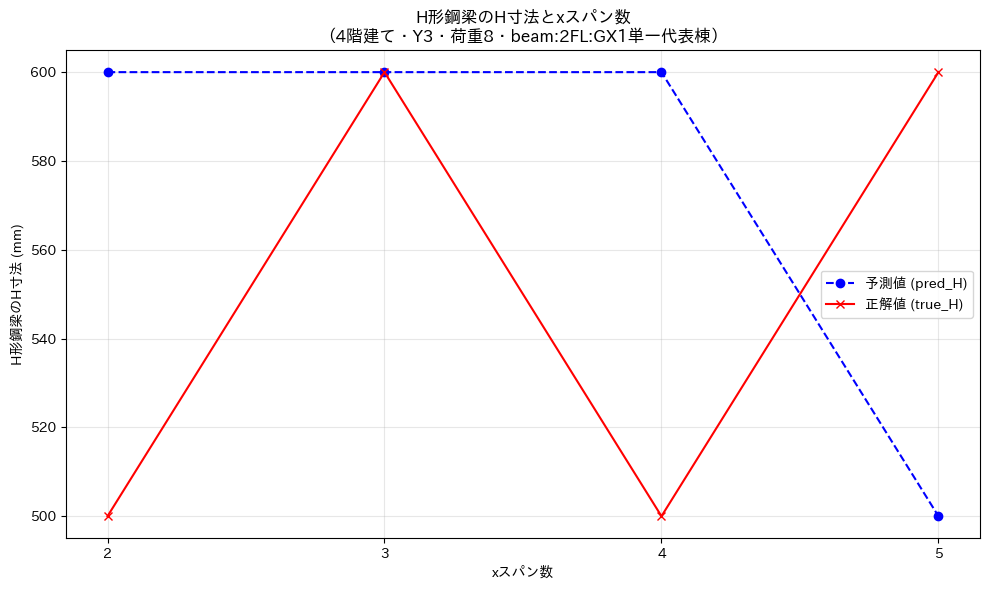

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
import os
import re
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# ============================================================
# 1. 保存先ディレクトリ
# ============================================================
save_dir = '/content/drive/MyDrive/research/DNN/Graphs'
os.makedirs(save_dir, exist_ok=True)

# ============================================================
# 2. file_name から建物の条件を抽出
#    例: 0006_4階_X2_Y3_荷重8.csv
# ============================================================
df = predictions.copy()

pattern = (
    r'(?P<id>\d+)_'
    r'(?P<floors>\d+)階_'
    r'X(?P<x_spans>\d+)_'
    r'Y(?P<y_spans>\d+)_'
    r'荷重(?P<load>\d+)'
)

extracted = df['file_name'].str.extract(pattern)

df['building_id'] = extracted['id']
df['階数'] = pd.to_numeric(extracted['floors'], errors='coerce')
df['xスパン数'] = pd.to_numeric(extracted['x_spans'], errors='coerce')
df['yスパン数'] = pd.to_numeric(extracted['y_spans'], errors='coerce')
df['荷重'] = pd.to_numeric(extracted['load'], errors='coerce')

# ============================================================
# 3. H形鋼の梁だけを抽出
# ============================================================
df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()

# H寸法が欠損しているデータを除外
df_h = df_h.dropna(
    subset=['xスパン数', 'pred_H', 'true_H']
)

# ============================================================
# 4. 比較する条件を指定
# ============================================================
target_floors = 4
target_y_spans = 3
target_load = 8

df_plot = df_h[
    (df_h['階数'] == target_floors) &
    (df_h['yスパン数'] == target_y_spans) &
    (df_h['荷重'] == target_load)
].copy()

if df_plot.empty:
    raise ValueError(
        '指定条件に一致するデータがありません。'
        '階数・Yスパン数・荷重を確認してください。'
    )

# ============================================================
# 5. xスパン数以外の条件を固定するため、指定の梁位置に絞り込み
# ============================================================
target_floor = '2FL'
target_slot = f'beam:{target_floor}:GX1'  # 梁位置を1つに固定

df_plot = df_plot[df_plot['slot'] == target_slot].copy()

if df_plot.empty:
    raise ValueError(
        f'{target_slot} のデータがありません。'
        'target_floor や target_slot を確認してください。'
    )

# ============================================================
# 6. 平均ではなく、各xスパン数における代表的な「1つの建物（建物ID）」の値を取得
# ============================================================
# 各xスパン数の中で、最初の1棟（最少のbuilding_idなど）のみを代表として抽出します
summary = (
    df_plot
    .sort_values(['xスパン数', 'building_id'])
    .groupby('xスパン数', as_index=False)
    .first()  # 平均値ではなく最初の1行（1つの具体的な値）を取得
    .sort_values('xスパン数')
)

# ============================================================
# 7. グラフの描画
# ============================================================
graph_title = (
    f'H形鋼梁のH寸法とxスパン数\n'
    f'（{target_floors}階建て・Y{target_y_spans}・荷重{target_load}・{target_slot}単一代表棟）'
)

plt.figure(figsize=(10, 6))

plt.plot(
    summary['xスパン数'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    label='予測値 (pred_H)'
)

plt.plot(
    summary['xスパン数'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    label='正解値 (true_H)'
)

plt.xlabel('xスパン数')
plt.ylabel('H形鋼梁のH寸法 (mm)')
plt.title(graph_title)
plt.xticks(sorted(summary['xスパン数'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# ============================================================
# 8. 保存・ダウンロード
# ============================================================
file_name = (
    f'H寸法_xスパン数_'
    f'{target_floors}階_Y{target_y_spans}_'
    f'荷重{target_load}_{target_slot}_single.png'
)

drive_path = os.path.join(save_dir, file_name)
plt.savefig(drive_path, dpi=300, bbox_inches='tight')

print(f'Google Driveへの保存先: {drive_path}')
print('\n単一建物データのプロット結果:')
print(summary[['xスパン数', 'building_id', 'pred_H', 'true_H']].to_string(index=False))

plt.show()

# PCへのダウンロード
files.download(drive_path)


##梁のDと荷重のグラフ

In [52]:
# 条件を満たすデータの件数
print('対象データ数:', len(df_plot))

# 建物IDごとの荷重の種類数
print(
    df_plot.groupby('building_id')['荷重']
    .agg(['count', 'nunique'])
    .sort_values('nunique')
)

# 荷重の種類
print('荷重一覧:', sorted(df_plot['荷重'].dropna().unique()))

# 建物IDごとに存在する荷重
print(
    df_plot.groupby('building_id')['荷重']
    .apply(lambda s: sorted(s.unique()))
)

対象データ数: 39
             count  nunique
building_id                
0006             1        1
0030             1        1
0076             1        1
0247             1        1
0266             1        1
0279             1        1
0463             1        1
0505             1        1
0507             1        1
0556             1        1
0700             1        1
0737             1        1
0816             1        1
0857             1        1
0939             1        1
0970             1        1
1065             1        1
1176             1        1
1441             1        1
2290             1        1
2294             1        1
2303             1        1
2346             1        1
2370             1        1
2611             1        1
2627             1        1
2667             1        1
2707             1        1
2803             1        1
2919             1        1
2935             1        1
2959             1        1
2975             1        1
2991     

荷重ごとの集計結果:
 荷重 building_id  pred_D  true_D
  6        0259   250.0   350.0
  7        0173   250.0   300.0
  8        0131   250.0   250.0

比較に使用した建物ID:
['0131', '0173', '0185', '0215', '0259', '0263', '0321', '0332', '0352', '0423', '0427', '0459', '0515', '0577', '0581', '0626', '0662', '0676', '0680', '0690', '0757', '0798', '0843', '0886', '0926', '0944', '1000', '1018', '1042', '1108', '1126', '1153', '1435', '1441', '1461']

Google Driveへの保存先: /content/drive/MyDrive/research/DNN/Graphs/柱D寸法_荷重_3階_X2_Y3_2FL_C1.png


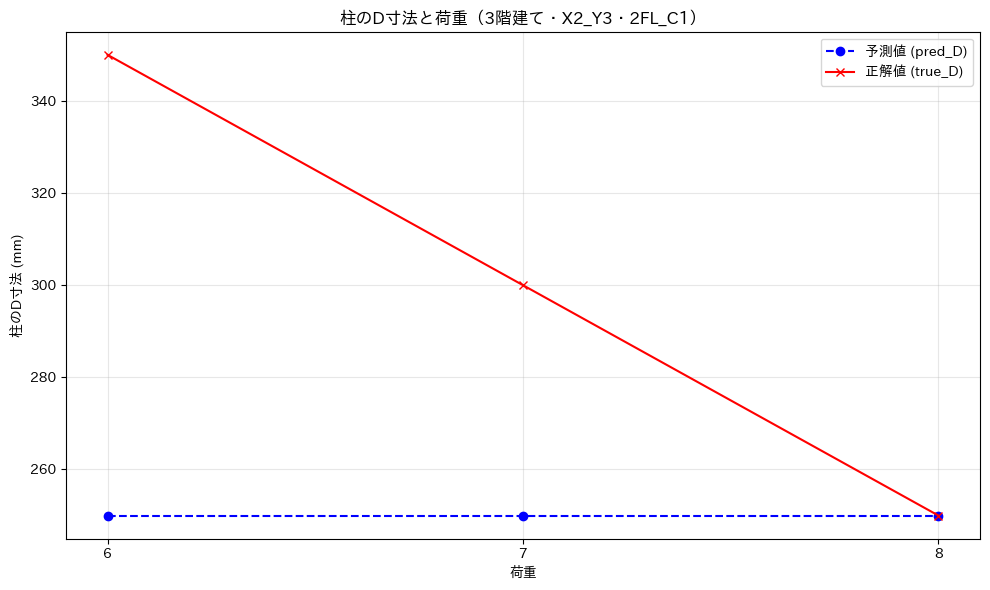

画像ファイル: /content/drive/MyDrive/research/DNN/Graphs/柱D寸法_荷重_3階_X2_Y3_2FL_C1.png
ファイルサイズ: 148,107 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:

import os
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# ============================================================
# 1. 保存先ディレクトリ
# ============================================================
save_dir = '/content/drive/MyDrive/research/DNN/Graphs'
os.makedirs(save_dir, exist_ok=True)

# ============================================================
# 2. file_name から建物条件を抽出
#    例: 0006_3階_X2_Y3_荷重8.csv
# ============================================================
df = predictions.copy()

pattern = (
    r'(?P<id>\d+)_'
    r'(?P<floors>\d+)階_'
    r'X(?P<x_spans>\d+)_'
    r'Y(?P<y_spans>\d+)_'
    r'荷重(?P<load>\d+)'
)

extracted = df['file_name'].str.extract(pattern)

df['building_id'] = extracted['id']
df['階数'] = pd.to_numeric(extracted['floors'], errors='coerce')
df['xスパン数'] = pd.to_numeric(extracted['x_spans'], errors='coerce')
df['yスパン数'] = pd.to_numeric(extracted['y_spans'], errors='coerce')
df['荷重'] = pd.to_numeric(extracted['load'], errors='coerce')

# ============================================================
# 3. 角形鋼管柱のデータを抽出
# ============================================================
df_col = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.startswith('column:', na=False))
].copy()

# 荷重・予測D寸法・正解D寸法が存在するデータに限定
df_col = df_col.dropna(
    subset=['荷重', 'pred_D', 'true_D']
)

# ============================================================
# 4. 荷重以外の条件を指定
# ============================================================
target_floors = 3
target_x_spans = 2
target_y_spans = 3
target_floor = '2FL'
target_column = 'C1'

df_plot = df_col[
    (df_col['階数'] == target_floors) &
    (df_col['xスパン数'] == target_x_spans) &
    (df_col['yスパン数'] == target_y_spans) &
    (
        df_col['slot']
        == f'column:{target_floor}:{target_column}'
    )
].copy()

if df_plot.empty:
    raise ValueError(
        '指定条件に一致するデータがありません。'
        '階数・X/Yスパン数・柱位置を確認してください。'
    )

# ============================================================
# 5. 荷重ごとにD寸法を集計
# ============================================================
# 同一条件・荷重に複数建物がある場合は平均せず、建物ID最小の1棟を代表にする。
summary = (df_plot.sort_values(['荷重','building_id','file_name'])
           .drop_duplicates('荷重', keep='first')
           [['荷重','building_id','pred_D','true_D']].sort_values('荷重'))

if summary.empty:
    raise ValueError('集計対象がありません。')

print('荷重ごとの集計結果:')
print(summary.to_string(index=False))

print('\n比較に使用した建物ID:')
print(sorted(df_plot['building_id'].dropna().unique()))

# ============================================================
# 6. グラフタイトル
# ============================================================
graph_title = (
    f'柱のD寸法と荷重'
    f'（{target_floors}階建て・'
    f'X{target_x_spans}_Y{target_y_spans}・'
    f'{target_floor}_{target_column}）'
)

# ============================================================
# 7. グラフの描画
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    summary['荷重'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    label='予測値 (pred_D)'
)

ax.plot(
    summary['荷重'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    label='正解値 (true_D)'
)

ax.set_xlabel('荷重')
ax.set_ylabel('柱のD寸法 (mm)')
ax.set_title(graph_title)
ax.set_xticks(sorted(summary['荷重'].unique()))
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

# ============================================================
# 8. Google Drive に保存
# ============================================================
file_name = (
    f'柱D寸法_荷重_'
    f'{target_floors}階_X{target_x_spans}_'
    f'Y{target_y_spans}_{target_floor}_{target_column}.png'
)

drive_path = os.path.join(save_dir, file_name)

fig.savefig(
    drive_path,
    dpi=300,
    bbox_inches='tight'
)

print(f'\nGoogle Driveへの保存先: {drive_path}')

# ============================================================
# 9. グラフを表示してPCへダウンロード
# ============================================================
plt.show()
# 画像ファイルを閉じる前に保存済みであることを確認
if os.path.exists(drive_path):
    print(f'画像ファイル: {drive_path}')
    print(f'ファイルサイズ: {os.path.getsize(drive_path):,} bytes')

    # Google ColabからローカルPCへダウンロード
    files.download(drive_path)
else:
    raise FileNotFoundError(
        f'画像ファイルが見つかりません: {drive_path}'
    )